# Credit Risk Scorecards: WOE, IV, and Calibrated PDs

**What you'll learn**

- The industry-standard scorecard pipeline end to end, implemented from scratch: fine
  classing → Weight of Evidence (WOE) transformation → Information Value (IV) screening →
  monotone coarse classing → logistic regression → a **points scorecard** with proper PDO
  scaling (`Points = Offset − Factor · ln(odds)`), printed as the table a credit committee
  actually signs off on.
- Evaluation the credit-risk way: **KS statistic**, **Gini** (= 2·AUC − 1), score
  distributions by class, rating grades with observed default rates per band — and why
  **calibration of scores to PD** is not optional (pricing, IFRS 9/CECL provisioning,
  Basel capital all consume the probability *level*, not the ranking).
- What a LightGBM challenger buys you over the scorecard on the same data — we quantify
  the AUC/Gini gap on a DGP with real interactions, find the scorecard *winning* at
  development-sample scale, and show with a learning curve why (and when that flips) —
  plus what the GBM costs: adverse-action reason codes from a points model vs SHAP,
  monitoring, and model-risk governance.
- **Reject inference**: you only observe outcomes for *approved* loans. We simulate the
  approval filter and measure how a model trained on approved-only degrades — in ranking
  and especially in calibration — on the through-the-door (TTD) population.
- The pitfalls that actually bite: IV inflated by over-fine binning, WOE tables fit
  before the train/test split (leakage), same-AUC-different-calibration portfolios, and
  the circularity of naive fuzzy augmentation.

**Why it matters in interviews**

- Credit-risk and fintech loops ask "walk me through building a scorecard" as a
  *structure* test: fine/coarse classing, WOE/IV, PDO scaling, KS/Gini, PSI monitoring.
  Candidates who only know `model.fit(X, y)` fail this round.
- "Why does everyone still use logistic regression in credit?" is a trade-off question
  about regulation (ECOA/Reg B adverse action, SR 11-7), monotonicity, and monitoring —
  not about AUC.
- "Your training data is only approved loans — is that a problem?" (reject inference) is
  a classic selection-bias screen that generalizes far beyond credit (hiring, insurance,
  content moderation).
- Calibration questions ("your AUC is great, why do we care about calibrated PDs?")
  separate people who have shipped risk models from people who have run Kaggle.

Related notebooks: probability calibration in depth in
[../04_ml_tabular/03_evaluation_calibration.ipynb](../04_ml_tabular/03_evaluation_calibration.ipynb),
SHAP mechanics in
[../04_ml_tabular/05_explainability_shap.ipynb](../04_ml_tabular/05_explainability_shap.ipynb),
leakage patterns in
[../04_ml_tabular/02_leakage_validation.ipynb](../04_ml_tabular/02_leakage_validation.ipynb).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import brentq
from scipy.special import expit, logit as logit_fn
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, brier_score_loss
from sklearn.calibration import calibration_curve
from statsmodels.stats.proportion import proportion_confint
import lightgbm as lgb
import shap

rng = np.random.default_rng(42)

plt.rcParams.update({
    "figure.figsize": (8.5, 4.2),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.autolayout": True,
})
pd.set_option("display.precision", 4)
pd.set_option("display.width", 140)
pd.set_option("display.max_rows", 120)

## 1. A retail credit portfolio with known ground truth

We simulate a **through-the-door (TTD)** population of card/loan applicants with the five
characteristics every retail scorecard uses in some form: income, debt-to-income (DTI),
recent delinquencies, revolving utilization, and tenure. Features are correlated through a
one-factor Gaussian copula (a latent "financial stress" factor), because in real bureau
data everything risk-related is correlated — that is what makes coefficient signs and
collinearity a live issue.

The true default-generating process is **monotone in every feature** (as credit risk
largely is: more utilization is never good news) but nonlinear — hinge effects for DTI
above 25% and utilization above 70% — and contains **two genuine interactions**: high
utilization is much worse with recent delinquency, and high DTI is much worse at low
income. The interactions are there on purpose: they are the structure a WOE + logistic
scorecard cannot represent and a GBM can, so the section 7 comparison is honest.

Two more deliberate ingredients: `app_hour` (hour of day the application arrived) — pure
noise, so the IV screen has something to reject — and `z_beh`, an **unobserved behavioral
risk driver** (think bank-statement cash-flow signals) that affects default but is *not*
available to any model we build. Real portfolios always have one, and it becomes the
villain of the reject-inference section. Target portfolio default rate: **~8%**.

In [2]:
def gen_applications(n, rng, income_mult=1.0, util_shift=0.0):
    """Simulate applicant features + true log-odds contribution (eta), via a one-factor
    Gaussian copula. income_mult / util_shift let us simulate a stressed vintage later."""
    F = rng.standard_normal(n)  # latent financial-stress factor

    def latent(loading):
        return loading * F + np.sqrt(1 - loading**2) * rng.standard_normal(n)

    u = stats.norm.cdf
    income = income_mult * np.exp(10.9 + 0.55 * latent(-0.40))            # median ~$54k
    dti = np.clip(0.05 + 0.55 * stats.beta.ppf(u(latent(0.55)), 2.2, 3.5), 0.01, 0.95)
    delinq_12m = stats.poisson.ppf(u(latent(0.50)), 0.4).astype(int)      # ~67% have 0
    utilization = np.clip(stats.beta.ppf(u(latent(0.60)), 1.4, 2.2) + util_shift, 0.0, 1.0)
    tenure_months = np.maximum(stats.gamma.ppf(u(latent(-0.35)), a=2.0, scale=36), 1).round().astype(int)
    app_hour = rng.integers(0, 24, n)                                     # pure noise
    z_beh = rng.standard_normal(n)      # unobserved behavioral risk (bank-statement signals)

    log_inc = np.log(income / 50_000.0)
    eta_x = (
        -0.80 * log_inc                                          # income protects (log scale)
        + 2.20 * np.clip(dti - 0.25, 0, None)                    # DTI hurts above 25%
        + 0.90 * (delinq_12m >= 1) + 0.35 * np.clip(delinq_12m - 1, 0, 3)  # big jump at 1st delinquency
        + 0.80 * utilization + 1.60 * np.clip(utilization - 0.70, 0, None) # steep above 70%
        - 0.010 * np.minimum(tenure_months, 120)                 # tenure protects, flattens at 10y
        + 2.50 * (delinq_12m >= 1) * np.clip(utilization - 0.40, 0, None)  # INTERACTION 1
        + 3.00 * np.clip(-log_inc, 0, None) * np.clip(dti - 0.35, 0, None) # INTERACTION 2
    )
    eta = eta_x + 0.55 * z_beh          # z_beh is invisible to every model below
    return pd.DataFrame({
        "income": income.round(0), "dti": dti.round(4), "delinq_12m": delinq_12m,
        "utilization": utilization.round(4), "tenure_months": tenure_months,
        "app_hour": app_hour, "z_beh": z_beh, "eta_x": eta_x, "eta": eta,
    })

N = 60_000
df = gen_applications(N, rng)

# Solve the intercept so the TTD default rate is 8% (banks fix this in reverse: they know
# their portfolio bad rate and want the simulation to match it).
alpha_true = brentq(lambda a: expit(a + df["eta"]).mean() - 0.08, -15, 5)
df["p_true"] = expit(alpha_true + df["eta"])
df["default"] = (rng.random(N) < df["p_true"]).astype(int)

FEATURES = ["income", "dti", "delinq_12m", "utilization", "tenure_months"]

print(f"true intercept alpha = {alpha_true:.3f}")
print(f"TTD default rate     = {df['default'].mean():.3%}   (target 8%)")
print(f"oracle AUC (p_true)  = {roc_auc_score(df['default'], df['p_true']):.4f}"
      "  <- ceiling; partly unreachable (p_true sees the unobserved z_beh)")
df[FEATURES + ["default"]].describe().T[["mean", "std", "min", "50%", "max"]]

true intercept alpha = -3.307
TTD default rate     = 7.890%   (target 8%)
oracle AUC (p_true)  = 0.8300  <- ceiling; partly unreachable (p_true sees the unobserved z_beh)


,mean,std,min,50%,max
income,62967.6129,38004.7356,5383.0000,53893.5000,636741.0000
dti,0.2627,0.1035,0.0513,0.2553,0.5908
delinq_12m,0.3998,0.6333,0.0000,0.0000,6.0000
utilization,0.3886,0.2278,0.0002,0.3643,0.9937
tenure_months,71.9616,50.7695,1.0000,61.0000,522.0000
default,0.0789,0.2696,0.0000,0.0000,1.0000


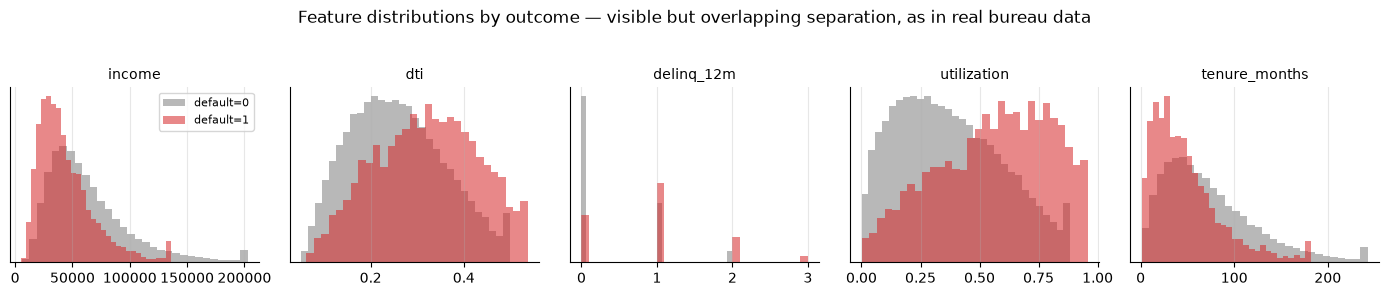

In [3]:
fig, axes = plt.subplots(1, 5, figsize=(14, 2.8))
for ax, f in zip(axes, FEATURES):
    for d, color in [(0, "tab:gray"), (1, "tab:red")]:
        x = df.loc[df["default"] == d, f]
        x = np.minimum(x, x.quantile(0.99))  # clip display tail only
        ax.hist(x, bins=30, density=True, alpha=0.55, color=color, label=f"default={d}")
    ax.set_title(f, fontsize=10)
    ax.set_yticks([])
axes[0].legend(fontsize=8)
fig.suptitle("Feature distributions by outcome — visible but overlapping separation, as in real bureau data", y=1.04)
plt.show()

## 2. Fine classing and WOE / IV, from scratch

The scorecard pipeline does not feed raw features to the model. Each characteristic is
**binned**, and each bin is replaced by its **Weight of Evidence**:

$$\mathrm{WOE}_i = \ln\frac{\%\,\text{goods in bin } i}{\%\,\text{bads in bin } i}, \qquad
\mathrm{IV} = \sum_i \left(\%\,\text{goods}_i - \%\,\text{bads}_i\right)\cdot \mathrm{WOE}_i$$

(Scorecard convention: **positive WOE = safer than average**. Some ML libraries flip the
ratio — state your convention in an interview.) WOE is the bin's contribution to the
log-odds relative to the portfolio average, which is exactly the scale logistic regression
works on. That is why the downstream fit behaves so well: each transformed feature is
already a univariate log-odds estimate, coefficients land near −1 with our convention,
and the model is robust to outliers and missing values (they just get their own bin).

**Fine classing** is step one: cut each feature into many small quantile bins (~20) purely
to *see* the risk pattern. The fine-class WOE curve is intentionally overfit — you read
it, you don't ship it.

In [4]:
def fine_edges(x, n_bins=20):
    """Quantile edges for fine classing; open-ended outer bins. Falls back to per-value
    bins for low-cardinality (discrete) features so ties don't swallow levels."""
    x = np.asarray(x, dtype=float)
    vals = np.unique(x)
    if vals.size <= n_bins:
        edges = np.concatenate([[-np.inf], (vals[:-1] + vals[1:]) / 2, [np.inf]])
    else:
        edges = np.unique(np.quantile(x, np.linspace(0, 1, n_bins + 1))).astype(float)
        edges[0], edges[-1] = -np.inf, np.inf
    return edges

def woe_table(x, y, edges, laplace=0.5):
    """Bin x by edges and compute counts, default rate, WOE and IV contribution per bin.
    Laplace smoothing keeps WOE finite in bins with zero goods or bads."""
    bins = pd.cut(np.asarray(x, dtype=float), edges, include_lowest=True)
    tab = (pd.DataFrame({"bin": bins, "y": np.asarray(y)})
           .groupby("bin", observed=False)["y"].agg(n="size", bads="sum"))
    tab["goods"] = tab["n"] - tab["bads"]
    G, B = tab["goods"].sum(), tab["bads"].sum()
    tab["count_pct"] = tab["n"] / tab["n"].sum()
    tab["default_rate"] = tab["bads"] / tab["n"].where(tab["n"] > 0)
    pct_g = (tab["goods"] + laplace) / (G + laplace * len(tab))
    pct_b = (tab["bads"] + laplace) / (B + laplace * len(tab))
    tab["woe"] = np.log(pct_g / pct_b)
    tab["iv_contrib"] = (pct_g - pct_b) * tab["woe"]
    return tab

def iv_of(tab):
    return tab["iv_contrib"].sum()

def apply_bin_values(x, edges, values):
    """Map raw x -> per-bin values (WOE or points). Open-ended edges => no unmapped rows."""
    codes = pd.cut(np.asarray(x, dtype=float), edges, include_lowest=True).codes
    return np.asarray(values)[codes]

# Discipline from the start: every table below is computed on TRAIN only.
df_train, df_test = train_test_split(df, test_size=0.5, stratify=df["default"], random_state=42)
y_train, y_test = df_train["default"].to_numpy(), df_test["default"].to_numpy()
print(f"train n={len(df_train):,} (bads={y_train.sum():,})   test n={len(df_test):,} (bads={y_test.sum():,})")

fine_u = woe_table(df_train["utilization"], y_train, fine_edges(df_train["utilization"], 20))
print("\nFine classing, utilization (20 quantile bins) — read the shape, don't ship it:")
fine_u[["n", "default_rate", "woe", "iv_contrib"]].round(4)

train n=30,000 (bads=2,367)   test n=30,000 (bads=2,367)

Fine classing, utilization (20 quantile bins) — read the shape, don't ship it:


,n,default_rate,woe,iv_contrib
bin,,,,
"(-inf, 0.0606]",1503,0.0220,1.3283,0.0519
"(0.0606, 0.102]",1499,0.0300,1.0112,0.0338
"(0.102, 0.138]",1502,0.0273,1.1080,0.0392
"(0.138, 0.17]",1496,0.0321,0.9432,0.0302
"(0.17, 0.202]",1502,0.0466,0.5580,0.0124
"(0.202, 0.234]",1501,0.0366,0.8070,0.0234
"(0.234, 0.266]",1507,0.0365,0.8111,0.0237
"(0.266, 0.297]",1491,0.0449,0.5959,0.0138
"(0.297, 0.329]",1499,0.0454,0.5861,0.0135


The fine-class curve shows the true monotone-decreasing WOE (risk rises with utilization,
so WOE falls), with sampling noise wiggling individual bins — some adjacent bins even
invert. Shipping those inversions would mean an applicant could *raise* their score by
*increasing* utilization: indefensible to a regulator and a symptom of overfit binning.

## 3. Monotone coarse classing

**Coarse classing** compresses fine bins into a handful of final bins under three
constraints that every scorecard shop enforces:

1. **Monotone default rate** across bins (unless there is a genuine U-shape with a
   business story — rare, and it must survive out-of-time validation).
2. **Minimum bin population** (here ≥ 5%) so WOE estimates are stable and the scorecard
   doesn't have brittle micro-bins.
3. **Business sense**: breakpoints a human can defend ("utilization above 70%"), and
   similar treatment of special values (missing bureau data gets its own bin in practice).

We implement monotone binning with the PAVA idea: fit an isotonic regression to fine-bin
default rates (direction picked by Spearman correlation with the target), then merge fine
bins that the isotonic fit pools together, then enforce the minimum-population constraint
by merging the smallest offenders into their nearest neighbor.

Coarse classing, utilization:
                   n  count_pct  default_rate     woe  iv_contrib
bin                                                              
(-inf, 0.0606]  1503     0.0501        0.0220  1.3262      0.0518
(0.0606, 0.17]  4497     0.1499        0.0298  1.0238      0.1036
(0.17, 0.329]   7500     0.2500        0.0420  0.6700      0.0851
(0.329, 0.397]  3003     0.1001        0.0519  0.4455      0.0165
(0.397, 0.471]  2997     0.0999        0.0604  0.2863      0.0073
(0.471, 0.511]  1501     0.0500        0.0919 -0.1687      0.0015
(0.511, 0.6]    2999     0.1000        0.1047 -0.3110      0.0110
(0.6, 0.652]    1500     0.0500        0.1193 -0.4593      0.0128
(0.652, inf]    4500     0.1500        0.2038 -1.0932      0.2812

IV fine = 0.6237   IV coarse = 0.5708   <- coarse gives up a little in-sample IV to buy stability


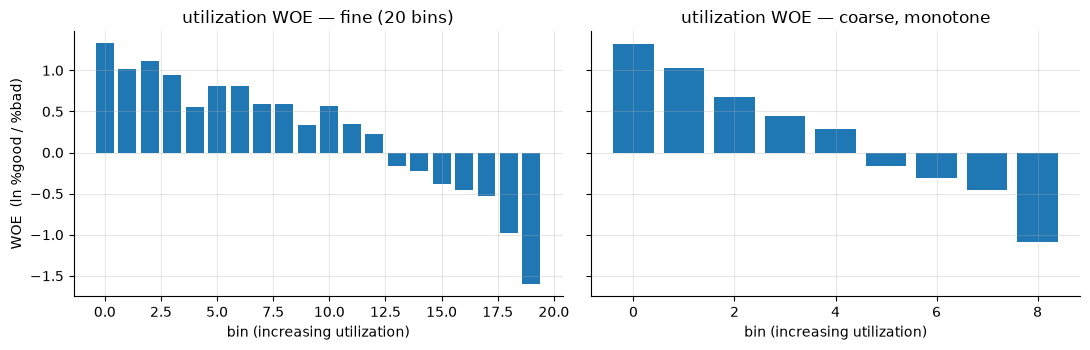

In [5]:
def monotone_coarse_edges(x, y, n_fine=20, min_frac=0.05):
    """Monotone (isotonic/PAVA) coarse classing on top of fine quantile bins."""
    x = np.asarray(x, dtype=float); y = np.asarray(y)
    edges = fine_edges(x, n_fine)
    bins = pd.cut(x, edges, include_lowest=True)
    g = (pd.DataFrame({"bin": bins, "y": y})
         .groupby("bin", observed=True)["y"].agg(["mean", "size"]).reset_index())
    rho = stats.spearmanr(x, y).statistic
    iso = IsotonicRegression(increasing=bool(rho > 0))
    pooled = iso.fit_transform(np.arange(len(g)), g["mean"].to_numpy(),
                               sample_weight=g["size"].to_numpy())
    # fine bins pooled to the same rate become one coarse bin
    group_id = np.concatenate([[0], np.cumsum(~np.isclose(np.diff(pooled), 0.0))])
    right = edges[1:]
    coarse = np.concatenate([[-np.inf],
                             [right[group_id == gid][-1] for gid in np.unique(group_id)]])
    # enforce minimum bin share by merging the smallest bin into a neighbour
    while True:
        counts = pd.Series(pd.cut(x, coarse, include_lowest=True)).value_counts(sort=False).to_numpy()
        frac = counts / counts.sum()
        if (frac >= min_frac).all() or len(coarse) <= 3:
            break
        i = int(frac.argmin())
        coarse = np.delete(coarse, i if i > 0 else 1)  # drop the interior edge next to bin i
    return coarse

edges_u = monotone_coarse_edges(df_train["utilization"], y_train)
coarse_u = woe_table(df_train["utilization"], y_train, edges_u)
print("Coarse classing, utilization:")
print(coarse_u[["n", "count_pct", "default_rate", "woe", "iv_contrib"]].round(4))
print(f"\nIV fine = {iv_of(fine_u):.4f}   IV coarse = {iv_of(coarse_u):.4f}"
      "   <- coarse gives up a little in-sample IV to buy stability")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, tab, name in [(axes[0], fine_u, "fine (20 bins)"), (axes[1], coarse_u, "coarse, monotone")]:
    ax.bar(range(len(tab)), tab["woe"], color="tab:blue")
    ax.set_title(f"utilization WOE — {name}")
    ax.set_xlabel("bin (increasing utilization)")
axes[0].set_ylabel("WOE  (ln %good / %bad)")
plt.show()

## 4. The IV screen

IV summarizes each characteristic's univariate strength on the WOE scale. The industry
rule of thumb (Siddiqi):

| IV | verdict |
|---|---|
| < 0.02 | useless — drop |
| 0.02 – 0.1 | weak |
| 0.1 – 0.3 | medium |
| 0.3 – 0.5 | strong |
| > 0.5 | **suspicious — check for leakage** |

The last row is the one seniors get asked about: an IV of 1.5 is not a great feature, it
is almost always information from *after* the outcome window (e.g., "months since last
payment" computed at snapshot including the default event). Section 9 shows how IV also
inflates mechanically with over-fine bins.

In [6]:
screen_feats = FEATURES + ["app_hour"]
edges_, tabs_ = {}, {}
for f in screen_feats:
    edges_[f] = monotone_coarse_edges(df_train[f], y_train)
    tabs_[f] = woe_table(df_train[f], y_train, edges_[f])

iv_summary = (pd.Series({f: iv_of(tabs_[f]) for f in screen_feats}, name="IV")
              .sort_values(ascending=False).to_frame())
iv_summary["n_bins"] = [len(tabs_[f]) for f in iv_summary.index]
iv_summary["verdict"] = pd.cut(iv_summary["IV"], [-np.inf, 0.02, 0.1, 0.3, 0.5, np.inf],
                               labels=["drop", "weak", "medium", "strong", "suspicious"])
print(iv_summary.round(4))
print("\napp_hour is correctly screened out (IV ~ 0). The five real characteristics survive.")

                   IV  n_bins     verdict
delinq_12m     0.7346       3  suspicious
utilization    0.5708       9  suspicious
income         0.4316      15      strong
tenure_months  0.3484       8      strong
dti            0.3273       9      strong
app_hour       0.0006       3        drop

app_hour is correctly screened out (IV ~ 0). The five real characteristics survive.


## 5. The logistic scorecard and PDO points scaling

Fit logistic regression on the WOE-transformed characteristics. With WOE defined as
ln(%good/%bad), each coefficient should come out **negative and near −1**: WOE is already
the univariate log-odds contribution, so the multivariate fit mostly shrinks it for
correlation with the other characteristics. A positive coefficient is a red flag
(collinearity or an unstable characteristic) — in practice you drop or re-bin, because a
reversed sign makes the points table indefensible.

In [7]:
def fit_scorecard(dtrain, y, features, n_fine=20, min_frac=0.05):
    """Full pipeline: monotone coarse classing + WOE tables + logistic on WOE features."""
    model = {"features": list(features), "edges": {}, "tabs": {}}
    W = np.empty((len(dtrain), len(features)))
    for j, f in enumerate(features):
        model["edges"][f] = monotone_coarse_edges(dtrain[f], y, n_fine, min_frac)
        model["tabs"][f] = woe_table(dtrain[f], y, model["edges"][f])
        W[:, j] = apply_bin_values(dtrain[f], model["edges"][f], model["tabs"][f]["woe"].to_numpy())
    # C=1e6 ~ unpenalized; version-proof alternative to penalty=None
    model["lr"] = LogisticRegression(C=1e6, max_iter=5000).fit(W, y)
    return model

def transform_woe(model, d):
    return np.column_stack([
        apply_bin_values(d[f], model["edges"][f], model["tabs"][f]["woe"].to_numpy())
        for f in model["features"]])

def predict_pd(model, d):
    return model["lr"].predict_proba(transform_woe(model, d))[:, 1]

sc = fit_scorecard(df_train, y_train, FEATURES)
coefs = pd.Series(sc["lr"].coef_[0], index=FEATURES, name="beta (on WOE)")
print(coefs.round(3))
print(f"intercept alpha = {sc['lr'].intercept_[0]:.3f}  (~ ln(bad/good) of the portfolio = "
      f"{np.log(y_train.mean() / (1 - y_train.mean())):.3f})")

income          -0.664
dti             -0.335
delinq_12m      -0.747
utilization     -0.595
tenure_months   -0.639
Name: beta (on WOE), dtype: float64
intercept alpha = -2.464  (~ ln(bad/good) of the portfolio = -2.457)


### From model to points: PDO scaling

A scorecard is a **linear rescaling of the model's log-odds** into points:

$$\text{Score} \;=\; \text{Offset} \;-\; \text{Factor}\cdot \ln(\text{odds of default}),
\qquad \text{Factor} = \frac{\text{PDO}}{\ln 2}$$

Two anchors pin it down: a reference score at a reference odds (here **600 points at 30:1
good:bad odds**) and the **PDO** — "points to double the odds" (here 20: every +20 points
halves the odds of default). Since
$\ln(\text{odds bad}) = \alpha + \sum_j \beta_j \mathrm{WOE}_j(x)$ is additive, the total
score decomposes into **points per bin**:

$$\text{points}_{j,\text{bin}} = \Big(-\beta_j\,\mathrm{WOE}_{j,\text{bin}} - \tfrac{\alpha}{k}\Big)\cdot\text{Factor} + \tfrac{\text{Offset}}{k}$$

where $k$ is the number of characteristics (intercept and offset spread evenly, the usual
convention). Rounding to integers costs a fraction of a point of accuracy and buys an
artifact that underwriting systems, regulators, and adverse-action letters can all
consume. This decomposition is *the* reason points scorecards are operationally loved.

In [8]:
def build_points(model, pdo=20.0, base_score=600.0, base_odds_good=30.0):
    """Attach integer points per bin to each WOE table; returns (factor, offset)."""
    factor = pdo / np.log(2)
    offset = base_score - factor * np.log(base_odds_good)  # score = offset - factor*ln(odds_bad)
    alpha = model["lr"].intercept_[0]
    k = len(model["features"])
    for j, f in enumerate(model["features"]):
        beta = model["lr"].coef_[0][j]
        pts = (-beta * model["tabs"][f]["woe"] - alpha / k) * factor + offset / k
        model["tabs"][f]["points"] = pts.round().astype(int)
    model["factor"], model["offset"] = factor, offset
    return factor, offset

def score_points(model, d):
    return sum(apply_bin_values(d[f], model["edges"][f], model["tabs"][f]["points"].to_numpy())
               for f in model["features"])

factor, offset = build_points(sc)
print(f"Factor = PDO/ln2 = {factor:.2f}   Offset = {offset:.2f}"
      f"   (600 pts at 30:1 good:bad, +20 pts halves default odds)")

# The scorecard table — the actual deliverable.
card = pd.concat(
    [sc["tabs"][f].reset_index().assign(characteristic=f) for f in FEATURES], ignore_index=True)
card["bin"] = card["bin"].astype(str)
card = card.set_index(["characteristic", "bin"])[["count_pct", "default_rate", "woe", "points"]]
print("\n================ SCORECARD (train development sample) ================")
print(card.round({"count_pct": 3, "default_rate": 3, "woe": 3}).to_string())

Factor = PDO/ln2 = 28.85   Offset = 501.86   (600 pts at 30:1 good:bad, +20 pts halves default odds)

================ SCORECARD (train development sample) ================
                                     count_pct  default_rate    woe  points
characteristic bin                                                         
income         (-inf, 21832.85]          0.050         0.223 -1.209      91
               (21832.85, 26805.9]       0.050         0.157 -0.778     100
               (26805.9, 30722.7]        0.050         0.138 -0.625     103
               (30722.7, 37394.5]        0.100         0.111 -0.372     107
               (37394.5, 40498.4]        0.050         0.099 -0.253     110
               (40498.4, 43578.65]       0.050         0.097 -0.230     110
               (43578.65, 46835.2]       0.050         0.073  0.088     116
               (46835.2, 53946.0]        0.100         0.066  0.194     118
               (53946.0, 61782.4]        0.100         0.065  0.209

In [9]:
# Sanity check: integer points vs the exact rescaled log-odds — rounding costs almost nothing.
score_test = score_points(sc, df_test)
pd_test = predict_pd(sc, df_test)
exact = offset - factor * logit_fn(pd_test)
print(f"max |integer score - exact score| = {np.abs(score_test - exact).max():.2f} points")
print(f"score range on test: {score_test.min()} .. {score_test.max()}")
df_test = df_test.assign(score=score_test, pd_hat=pd_test)

max |integer score - exact score| = 1.99 points
score range on test: 477 .. 676


## 6. Evaluation the credit-risk way

Credit risk speaks **KS** and **Gini**, not accuracy or F1:

- **KS** = max over cutoffs of |CDF_bads(score) − CDF_goods(score)|: the single best
  cutoff's separation. Retail scorecards typically land at KS 25–45.
- **Gini = 2·AUC − 1** (a.k.a. accuracy ratio): ranking quality across *all* cutoffs.
- **Rating grades**: scores are banded into grades; each grade must show a monotone,
  materially different observed default rate — that table is what pricing, provisioning
  and capital consume.

test AUC = 0.8049   Gini = 0.6098   KS = 0.466 at score 572


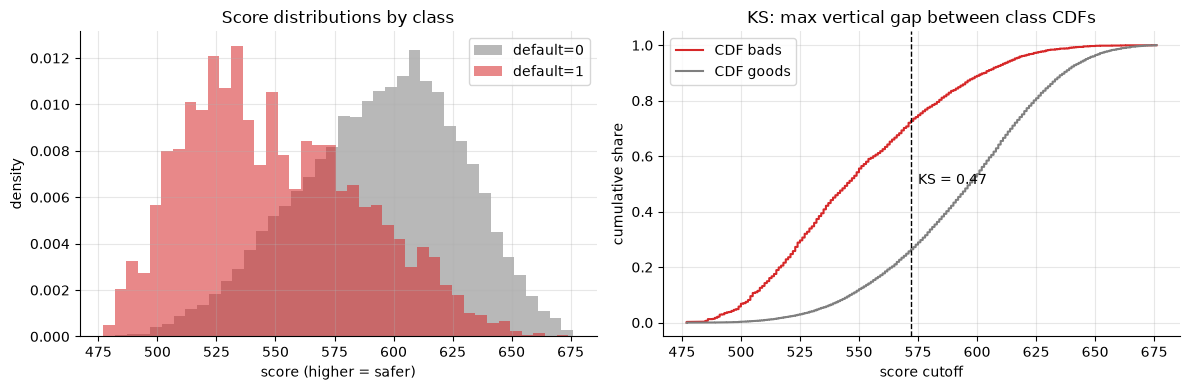

In [10]:
def ks_statistic(score, y):
    """KS on a score where higher = safer. Returns (ks, score at max separation)."""
    s, yy = np.asarray(score), np.asarray(y)
    order = np.argsort(s)
    s, yy = s[order], yy[order]
    cum_bad = np.cumsum(yy) / yy.sum()
    cum_good = np.cumsum(1 - yy) / (len(yy) - yy.sum())
    gap = cum_bad - cum_good           # bads pile up at low scores first
    i = int(np.argmax(gap))
    return gap[i], s[i], s, cum_bad, cum_good

ks, ks_at, s_sorted, cb, cg = ks_statistic(df_test["score"], y_test)
auc_sc = roc_auc_score(y_test, df_test["pd_hat"])
print(f"test AUC = {auc_sc:.4f}   Gini = {2 * auc_sc - 1:.4f}   KS = {ks:.3f} at score {ks_at}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for d, color in [(0, "tab:gray"), (1, "tab:red")]:
    axes[0].hist(df_test.loc[y_test == d, "score"], bins=40, density=True,
                 alpha=0.55, color=color, label=f"default={d}")
axes[0].set(title="Score distributions by class", xlabel="score (higher = safer)", ylabel="density")
axes[0].legend()
axes[1].plot(s_sorted, cb, color="tab:red", label="CDF bads")
axes[1].plot(s_sorted, cg, color="tab:gray", label="CDF goods")
axes[1].axvline(ks_at, ls="--", color="k", lw=1)
axes[1].annotate(f"KS = {ks:.2f}", (ks_at + 3, 0.5))
axes[1].set(title="KS: max vertical gap between class CDFs", xlabel="score cutoff", ylabel="cumulative share")
axes[1].legend()
plt.show()

          n  score_lo  score_hi  obs_default_rate         dr_ci95  mean_pd_hat
grade                                                                         
G1     3667       633       676            0.0104  [0.008, 0.014]       0.0072
G2     3592       619       632            0.0164  [0.013, 0.021]       0.0138
G3     3877       607       618            0.0279  [0.023, 0.034]       0.0213
G4     3771       595       606            0.0342  [0.029, 0.041]       0.0317
G5     3712       582       594            0.0474  [0.041, 0.055]       0.0480
G6     3738       567       581            0.0690  [0.061, 0.078]       0.0753
G7     3843       546       566            0.1059  [0.097, 0.116]       0.1317
G8     3800       477       545            0.3137  [0.299, 0.329]       0.3053


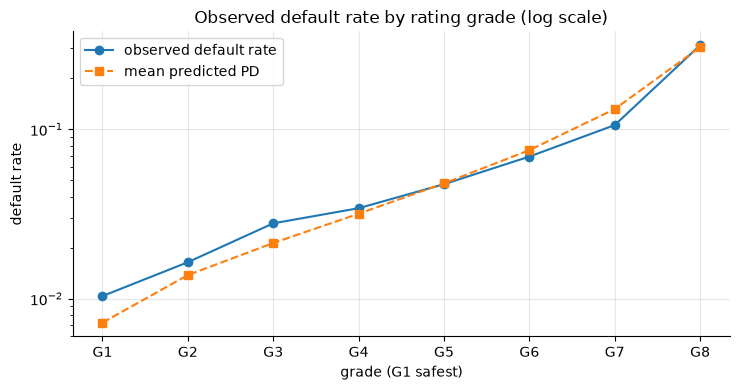

In [11]:
# Rating grades: band the score, check monotone observed default rates with binomial CIs,
# and compare against the mean predicted PD per grade (grade-level calibration).
gedges = np.unique(np.quantile(df_test["score"], np.linspace(0, 1, 9))).astype(float)
gedges[0], gedges[-1] = -np.inf, np.inf
k_g = len(gedges) - 1
labels = [f"G{k_g - i}" for i in range(k_g)]              # G8 = riskiest ... G1 = safest
grade = pd.cut(df_test["score"], gedges, labels=labels, include_lowest=True)

gt = (df_test.assign(grade=grade)
      .groupby("grade", observed=True)
      .agg(n=("default", "size"), bads=("default", "sum"),
           score_lo=("score", "min"), score_hi=("score", "max"),
           mean_pd_hat=("pd_hat", "mean"))
      .iloc[::-1])                                        # show safest first
gt["obs_default_rate"] = gt["bads"] / gt["n"]
ci = proportion_confint(gt["bads"], gt["n"], method="wilson")
gt["dr_ci95"] = [f"[{lo:.3f}, {hi:.3f}]" for lo, hi in zip(ci[0], ci[1])]
print(gt[["n", "score_lo", "score_hi", "obs_default_rate", "dr_ci95", "mean_pd_hat"]]
      .round(4).to_string())

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(gt.index, gt["obs_default_rate"], "o-", label="observed default rate")
ax.plot(gt.index, gt["mean_pd_hat"], "s--", color="tab:orange", label="mean predicted PD")
ax.set_yscale("log")
ax.set(title="Observed default rate by rating grade (log scale)", xlabel="grade (G1 safest)",
       ylabel="default rate")
ax.legend()
plt.show()

The grade curve is close to a straight line on the log scale — that is the PDO structure
showing through (each ~20 points halves the odds), and predicted PDs track observed rates
per grade. That second property is **calibration**, and it is where the money is:

- **Pricing**: risk-based APR must cover expected loss ≈ PD × LGD. If PD is off 30%, you
  under-price risk and get adversely selected, or over-price and lose the good customers.
- **Provisioning**: IFRS 9 / CECL expected credit loss = PD × LGD × EAD flows straight to
  the P&L. Miscalibrated PDs are misstated earnings.
- **Capital**: Basel IRB risk weights are a formula *in the PD level*. Regulators test
  calibration per grade (binomial tests), not AUC.

AUC is invariant to any monotone transform of the score; **expected loss is not**. Here is
the same ranking with distorted calibration — identical AUC, materially different P&L:

                         AUC   Brier  mean PD  expected loss ($M)
calibrated scorecard  0.8049  0.0615   0.0801             17.3108
miscalibrated twin    0.8049  0.0885   0.1575             34.0192
realized loss on test portfolio: $17.0M (n=30,000 loans x $12,000 EAD x 0.6 LGD)


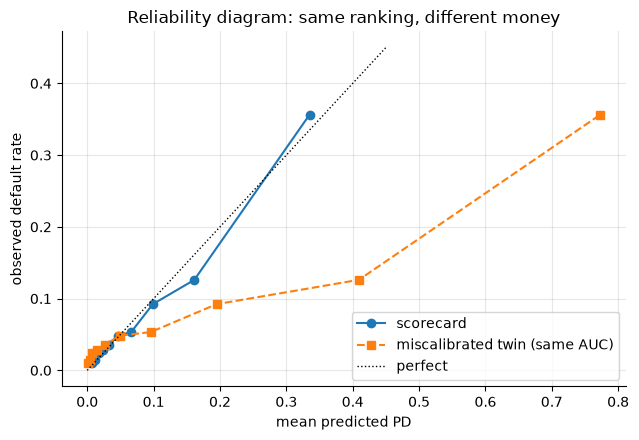

In [12]:
# A monotone distortion of the logit: same ranking (same AUC/Gini/KS), different PD levels.
lg = logit_fn(df_test["pd_hat"].to_numpy())
pd_miscal = expit(1.9 * (lg - lg.mean()) + lg.mean())

LGD, EAD = 0.60, 12_000  # loss given default, exposure at default ($)
summary = pd.DataFrame({
    "AUC": [roc_auc_score(y_test, df_test["pd_hat"]), roc_auc_score(y_test, pd_miscal)],
    "Brier": [brier_score_loss(y_test, df_test["pd_hat"]), brier_score_loss(y_test, pd_miscal)],
    "mean PD": [df_test["pd_hat"].mean(), pd_miscal.mean()],
    "expected loss ($M)": [(df_test["pd_hat"] * LGD * EAD).sum() / 1e6,
                           (pd_miscal * LGD * EAD).sum() / 1e6],
}, index=["calibrated scorecard", "miscalibrated twin"])
realized = y_test.sum() * LGD * EAD / 1e6
print(summary.round(4).to_string())
print(f"realized loss on test portfolio: ${realized:.1f}M "
      f"(n={len(df_test):,} loans x ${EAD:,} EAD x {LGD} LGD)")

frac_cal, mean_cal = calibration_curve(y_test, df_test["pd_hat"], n_bins=10, strategy="quantile")
frac_mis, mean_mis = calibration_curve(y_test, pd_miscal, n_bins=10, strategy="quantile")
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.plot(mean_cal, frac_cal, "o-", label="scorecard")
ax.plot(mean_mis, frac_mis, "s--", color="tab:orange", label="miscalibrated twin (same AUC)")
ax.plot([0, 0.45], [0, 0.45], "k:", lw=1, label="perfect")
ax.set(title="Reliability diagram: same ranking, different money", xlabel="mean predicted PD",
       ylabel="observed default rate")
ax.legend()
plt.show()

**Monitoring in one cell — PSI.** Scorecards live for years; the population drifts. The
Population Stability Index compares the current score distribution to development
(same formula as IV, applied to score deciles). Rule of thumb: < 0.1 stable, 0.1–0.25
investigate, > 0.25 the scorecard population has shifted materially (re-develop or
re-calibrate). Here: a recession vintage — incomes down 28%, utilization up 18 points.

In [13]:
def psi(expected, actual, edges):
    e = np.histogram(expected, edges)[0] / len(expected)
    a = np.histogram(actual, edges)[0] / len(actual)
    e, a = np.clip(e, 1e-4, None), np.clip(a, 1e-4, None)
    return float(np.sum((a - e) * np.log(a / e)))

stressed = gen_applications(20_000, rng, income_mult=0.72, util_shift=0.18)
stressed_score = score_points(sc, stressed)
psi_edges = np.unique(np.quantile(df_test["score"], np.linspace(0, 1, 11))).astype(float)
psi_edges[0], psi_edges[-1] = -np.inf, np.inf
psi_val = psi(df_test["score"], stressed_score, psi_edges)
verdict = ("stable (<0.1)" if psi_val < 0.1
           else "investigate (0.1-0.25)" if psi_val < 0.25 else "material shift (>0.25)")
print(f"PSI(dev -> stressed vintage) = {psi_val:.3f}   -> {verdict}")
print("The score distribution has moved; the dev-sample PD calibration should not be trusted"
      "\nuntil grade-level default rates are re-checked on the new population.")

PSI(dev -> stressed vintage) = 0.200   -> investigate (0.1-0.25)
The score distribution has moved; the dev-sample PD calibration should not be trusted
until grade-level default rates are re-checked on the new population.


## 7. Scorecard vs GBM: what does the black box buy?

Now the question every credit team faces: fit LightGBM on the **raw** features and measure
the gap. Our DGP has hinge nonlinearities (which WOE binning captures well — that's the
point of binning) and two interactions — delinquency × utilization, income × DTI — which
an additive points model *cannot* represent. So the GBM must win, right?

Two useful reference rows in the comparison: the **feature ceiling** (rank by the true
feature-only log-odds `eta_x` — the best *any* model on these five features can do) and
the **oracle** (true PD, which also sees the unobserved `z_beh` — unreachable by
construction).

In [14]:
gbm = lgb.LGBMClassifier(n_estimators=800, learning_rate=0.03, num_leaves=8,
                         min_child_samples=200, subsample=0.9, colsample_bytree=0.9,
                         random_state=42, verbose=-1)
gbm.fit(df_train[FEATURES], y_train)
pd_gbm = gbm.predict_proba(df_test[FEATURES])[:, 1]

rows = {}
for name, p in [("scorecard (WOE + logistic)", df_test["pd_hat"]),
                ("LightGBM (raw features)", pd_gbm),
                ("feature ceiling (true eta_x)", df_test["eta_x"]),
                ("oracle (true PD, sees z_beh)", df_test["p_true"])]:
    auc = roc_auc_score(y_test, p)
    ks_m = ks_statistic(-np.asarray(p), y_test)[0]
    rows[name] = {"AUC": auc, "Gini": 2 * auc - 1, "KS": ks_m}
comp = pd.DataFrame(rows).T
comp["Gini gap vs scorecard"] = comp["Gini"] - comp.loc["scorecard (WOE + logistic)", "Gini"]
print(comp.round(4).to_string())

                                 AUC    Gini      KS  Gini gap vs scorecard
scorecard (WOE + logistic)    0.8049  0.6098  0.4657                 0.0000
LightGBM (raw features)       0.8024  0.6047  0.4646                -0.0051
feature ceiling (true eta_x)  0.8096  0.6191  0.4676                 0.0093
oracle (true PD, sees z_beh)  0.8291  0.6581  0.5026                 0.0483


Surprise with a lesson in it: **at development-sample scale the challenger loses.** Read
the ceiling row: the additive scorecard already sits within about one Gini point of
the best achievable from these five features. The reason is that our characteristics are
*correlated* (the copula factor) and individually monotone, so the marginal WOE curves
absorb most of each interaction's signal — the interaction's *unique* contribution to
ranking is tiny. The GBM has to pay estimation variance to chase that sliver, and at
~30k training loans variance exceeds sliver. Most of the visible gap to the oracle is the
unobserved behavioral driver — no model class can buy it back.

So when *does* the GBM win? With enough data to price the interactions:

        scorecard  LightGBM
n_dev                      
5000       0.7975    0.7717
20000      0.7996    0.7919
60000      0.7990    0.7979
150000     0.7990    0.8013


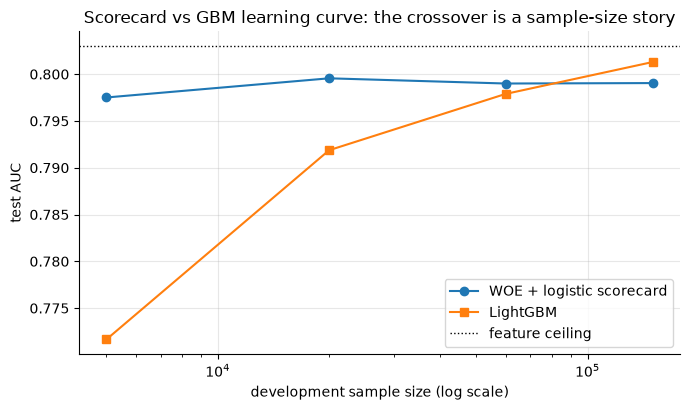

In [15]:
# Learning curve: same DGP, growing development sample, fixed 50k-applicant test set.
pool = gen_applications(250_000, rng)
pool["default"] = (rng.random(len(pool)) < expit(alpha_true + pool["eta"])).astype(int)
lc_test, lc_pool = pool.iloc[:50_000], pool.iloc[50_000:]
y_lc = lc_test["default"].to_numpy()

lc = []
for n_dev in [5_000, 20_000, 60_000, 150_000]:
    d = lc_pool.iloc[:n_dev]
    auc_s = roc_auc_score(y_lc, predict_pd(fit_scorecard(d, d["default"].to_numpy(), FEATURES), lc_test))
    g = lgb.LGBMClassifier(n_estimators=800, learning_rate=0.03, num_leaves=8,
                           min_child_samples=200, subsample=0.9, colsample_bytree=0.9,
                           random_state=42, verbose=-1).fit(d[FEATURES], d["default"])
    auc_g = roc_auc_score(y_lc, g.predict_proba(lc_test[FEATURES])[:, 1])
    lc.append({"n_dev": n_dev, "scorecard": auc_s, "LightGBM": auc_g})
lc = pd.DataFrame(lc).set_index("n_dev")
print(lc.round(4).to_string())

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(lc.index, lc["scorecard"], "o-", label="WOE + logistic scorecard")
ax.plot(lc.index, lc["LightGBM"], "s-", color="tab:orange", label="LightGBM")
ax.axhline(roc_auc_score(y_lc, lc_test["eta_x"]), ls=":", color="k", lw=1, label="feature ceiling")
ax.set_xscale("log")
ax.set(title="Scorecard vs GBM learning curve: the crossover is a sample-size story",
       xlabel="development sample size (log scale)", ylabel="test AUC")
ax.legend()
plt.show()

The scorecard is nearly flat from 5k loans on — WOE binning plus a linear fit is extremely
sample-efficient, which is exactly what a mid-size lender with a few thousand defaults
needs. The GBM starts far behind, crosses over somewhere in the tens of thousands, and
only then starts collecting the interaction sliver. The 1–3 Gini points GBMs earn in
industry come from **wide** data — hundreds of bureau attributes with messy, non-monotone
marginals and missing-value structure — not from out-modeling a well-built scorecard on
five clean characteristics. Whether any of it is worth taking is a *governance* question:

| | Points scorecard | GBM |
|---|---|---|
| Adverse action (ECOA / Reg B) | exact, from the points table | SHAP-based, approximated |
| Monotonicity | guaranteed by binning | must be constrained explicitly |
| Monitoring | PSI per characteristic, legible drift | distribution drift harder to attribute |
| Recalibration | shift the intercept/offset | often needs refit |
| Model risk (SR 11-7) validation | cheap | expensive |
| Ranking power | good | better (interactions) |

In practice: scorecard as champion for regulated origination decisions, GBM as challenger
and for lower-governance uses (collections queueing, fraud, line management). A monotone-
constrained GBM (`monotone_constraints` in LightGBM) with SHAP reason codes is the modern
middle ground — see [../04_ml_tabular/01_gradient_boosting_mastery.ipynb](../04_ml_tabular/01_gradient_boosting_mastery.ipynb).

### Adverse-action reason codes: points model vs SHAP

US law requires telling a declined applicant the **principal reasons**. With a points
model this is arithmetic: for each characteristic, compute the shortfall between the
applicant's points and the maximum attainable points; the top shortfalls are the reasons.
Deterministic, auditable, and monotone-consistent (paying down utilization can never
*lower* the score).

In [16]:
REASON_TEXT = {
    "income": "Income insufficient for amount of credit requested",
    "dti": "Debt-to-income ratio too high",
    "delinq_12m": "Recent delinquency on credit obligations",
    "utilization": "Proportion of revolving balances to credit limits too high",
    "tenure_months": "Limited tenure / length of credit history",
}

applicant = df_test.loc[df_test["score"].idxmin()]  # the most clearly declined applicant
print("Declined applicant:", {f: round(float(applicant[f]), 3) for f in FEATURES},
      f"\nscore = {int(applicant['score'])}, PD = {applicant['pd_hat']:.1%}\n")

shortfall = {}
for f in FEATURES:
    pts = apply_bin_values([applicant[f]], sc["edges"][f], sc["tabs"][f]["points"].to_numpy())[0]
    shortfall[f] = int(sc["tabs"][f]["points"].max() - pts)
reasons = pd.Series(shortfall, name="points below max").sort_values(ascending=False)
print("Points-based reason codes (top 3):")
for i, (f, s) in enumerate(reasons.head(3).items(), 1):
    print(f"  {i}. {REASON_TEXT[f]}  (-{s} points vs best bin)")

# SHAP reason codes for the SAME applicant under the GBM.
import warnings
explainer = shap.TreeExplainer(gbm)
with warnings.catch_warnings():
    # shap emits an informational UserWarning about its own binary-classifier output
    # format; the two lines below handle both formats explicitly.
    warnings.simplefilter("ignore", UserWarning)
    sv = explainer.shap_values(applicant[FEATURES].to_frame().T.astype(float))
sv = sv[1] if isinstance(sv, list) else sv          # binary-classifier API differences
sv = sv[..., 1] if np.ndim(sv) == 3 else sv
shap_reasons = pd.Series(sv.ravel(), index=FEATURES, name="SHAP (log-odds toward default)")
print("\nSHAP reason codes under the GBM (top 3 pushing toward default):")
print(shap_reasons.sort_values(ascending=False).head(3).round(3).to_string())

Declined applicant: {'income': 20317.0, 'dti': 0.531, 'delinq_12m': 2.0, 'utilization': 0.702, 'tenure_months': 15.0} 
score = 477, PD = 69.7%

Points-based reason codes (top 3):
  1. Income insufficient for amount of credit requested  (-52 points vs best bin)
  2. Recent delinquency on credit obligations  (-48 points vs best bin)
  3. Proportion of revolving balances to credit limits too high  (-41 points vs best bin)

SHAP reason codes under the GBM (top 3 pushing toward default):
delinq_12m    1.220
income        0.781
dti           0.680


Both approaches name similar drivers here — but note the differences a regulator will ask
about. SHAP values depend on a **baseline population** and share out interaction effects
(the delinquency × utilization interaction lands partly on each feature); two applicants
with identical utilization can receive different utilization attributions. The points
shortfall is a fixed, published mapping. SHAP mechanics, baselines and their pitfalls are
covered in [../04_ml_tabular/05_explainability_shap.ipynb](../04_ml_tabular/05_explainability_shap.ipynb).

## 8. Reject inference: you never see the outcomes you filtered out

Everything above quietly assumed we observe defaults for the whole TTD population. Real
banks don't: **only approved loans have outcomes**. The training population is filtered by
the *previous* credit policy, which approved low-risk applicants — so a model trained on
approved-only estimates $P(\text{default} \mid \text{approved})$, on a truncated feature
range, and is then deployed on everyone who walks in.

The key distinction (this is the senior-level point): if the old policy selected **only on
variables your new model also uses**, then approval ⊥ default given $x$ — you lose sample
in the risky region (variance) but $P(\text{default}\mid x)$ is still estimated without
bias. The damage comes from selection on things your model does *not* see. Real legacy
policies always contain such things: underwriter judgment, bank-statement reviews, old
bureau attributes you dropped. Our legacy policy scores DTI, delinquency and income — but
the underwriters also saw part of `z_beh`, the behavioral signal our features omit.

We approve 60%, develop a scorecard on approved-only — WOE tables *and* logistic fit,
exactly as a bank would — and compare against the full-population scorecard on the TTD
test set, which only a simulation lets us do.

In [17]:
log_inc_tr = np.log(df_train["income"] / 50_000)
legacy_train = (2.5 * df_train["dti"] + 1.2 * (df_train["delinq_12m"] >= 1)
                - 0.9 * log_inc_tr + 0.8 * df_train["z_beh"]   # underwriters saw soft info
                + rng.normal(0, 0.6, len(df_train)))
approved = (legacy_train <= np.quantile(legacy_train, 0.60)).to_numpy()

print(f"approval rate: {approved.mean():.0%}")
print(f"default rate | approved: {y_train[approved].mean():.2%}"
      f"   | rejected: {y_train[~approved].mean():.2%}   | TTD: {y_train.mean():.2%}")

sc_appr = fit_scorecard(df_train[approved], y_train[approved], FEATURES)
build_points(sc_appr)

# The bank's view (approved-only test proxy: approved rows of the test set)
log_inc_te = np.log(df_test["income"] / 50_000)
legacy_test = (2.5 * df_test["dti"] + 1.2 * (df_test["delinq_12m"] >= 1)
               - 0.9 * log_inc_te + 0.8 * df_test["z_beh"]
               + rng.normal(0, 0.6, len(df_test)))
appr_te = (legacy_test <= np.quantile(legacy_test, 0.60)).to_numpy()

pd_appr_model_ttd = predict_pd(sc_appr, df_test)
res = pd.DataFrame({
    "AUC on approved-only test (what the bank sees)": [
        roc_auc_score(y_test[appr_te], predict_pd(sc_appr, df_test[appr_te])),
        roc_auc_score(y_test[appr_te], df_test.loc[appr_te, "pd_hat"])],
    "AUC on full TTD test (what actually matters)": [
        roc_auc_score(y_test, pd_appr_model_ttd),
        roc_auc_score(y_test, df_test["pd_hat"])],
    "mean predicted PD on TTD": [pd_appr_model_ttd.mean(), df_test["pd_hat"].mean()],
}, index=["trained on APPROVED only", "trained on full TTD (oracle luxury)"]).T
print("\n" + res.round(4).to_string())
print(f"\nobserved TTD default rate: {y_test.mean():.2%}")

approval rate: 60%
default rate | approved: 3.12%   | rejected: 15.05%   | TTD: 7.89%



                                                trained on APPROVED only  trained on full TTD (oracle luxury)
AUC on approved-only test (what the bank sees)                    0.7087                               0.7093
AUC on full TTD test (what actually matters)                      0.7995                               0.8049
mean predicted PD on TTD                                          0.0503                               0.0801

observed TTD default rate: 7.89%


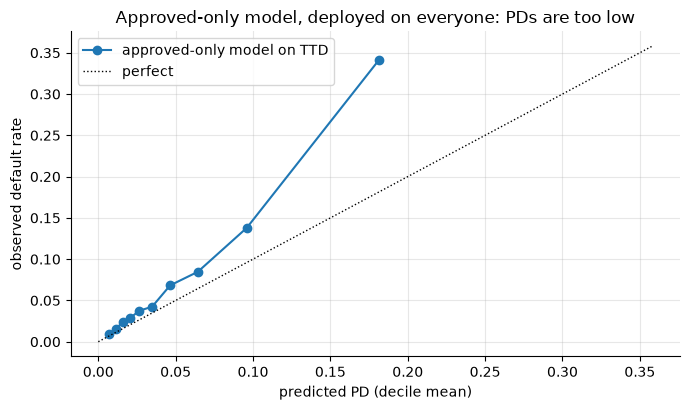

portfolio PD predicted by approved-only model: 5.03%  vs observed TTD: 7.89%
-> underwriting, pricing and provisioning would all be set against understated risk.


In [18]:
# Where it hurts most: calibration on the through-the-door population.
dec = pd.qcut(pd_appr_model_ttd, 10, labels=False, duplicates="drop")
cal_tab = (pd.DataFrame({"decile": dec, "pred": pd_appr_model_ttd, "y": y_test})
           .groupby("decile", observed=True).agg(pred_pd=("pred", "mean"), obs_dr=("y", "mean")))
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(cal_tab["pred_pd"], cal_tab["obs_dr"], "o-", label="approved-only model on TTD")
lim = max(cal_tab["obs_dr"].max(), cal_tab["pred_pd"].max()) * 1.05
ax.plot([0, lim], [0, lim], "k:", lw=1, label="perfect")
ax.set(title="Approved-only model, deployed on everyone: PDs are too low",
       xlabel="predicted PD (decile mean)", ylabel="observed default rate")
ax.legend()
plt.show()
print(f"portfolio PD predicted by approved-only model: {pd_appr_model_ttd.mean():.2%}"
      f"  vs observed TTD: {y_test.mean():.2%}"
      "\n-> underwriting, pricing and provisioning would all be set against understated risk.")

Ranking degrades only mildly (the approved sample is thin on delinquent, high-DTI
applicants, so those WOE estimates are noisy and attenuated); **calibration degrades
systematically** — within every feature bin, the approved were the ones with good soft
information, so the model's PDs describe a cleaner population than the one walking in the
door. And note the trap inside the trap: on the approved-only test set the bank's metrics
look *fine*. The damage is invisible in the data the bank has. With hard policy cutoffs
(no underwriter noise) it is worse still: entire feature regions have zero outcome data
and the model extrapolates freely.

**Reject-inference approaches** (what to name in an interview):

- **Augmentation / reweighting**: weight approved loans by inverse probability of approval
  (Heckman-flavored) to represent the TTD population.
- **Fuzzy augmentation**: score the rejects with the approved-only model; add each reject
  twice (as good with weight 1−p̂, as bad with weight p̂) and refit. Exercise 3 shows the
  circularity problem with this.
- **Parceling / hard-cutoff augmentation**: assign reject outcomes by band, often with a
  prudential multiplier on the inferred bad rate (e.g., "rejects are 2× the bad rate the
  model claims").
- **Bureau performance proxies**: observe how your rejects performed on loans they got
  *elsewhere* — the strongest practical fix.
- **Randomized swap-set approvals**: approve a small random slice below cutoff. The only
  method that produces unbiased outcome data — it buys information with credit losses,
  and pricing that trade-off is a genuinely senior conversation.

## 9. Pitfalls, demonstrated

### Pitfall 1: IV inflates mechanically with over-fine binning

IV is computed from in-sample bin frequencies; with many bins each bin chases noise, and
noise always points "the right way" in-sample. A pure-noise feature can post a "medium"
IV if you bin it hard on a modest sample. The fix: coarse bins with minimum population,
and if in doubt compute WOE on one half and IV on the other.

In [19]:
n_small = 3_000
noise = rng.standard_normal(n_small)
y_small = df_train["default"].to_numpy()[:n_small]

rows = []
for nb in [5, 20, 50, 100]:
    tab_in = woe_table(noise, y_small, fine_edges(noise, nb))
    # honest version: WOE from first half, IV evaluated on second half
    half = n_small // 2
    e = fine_edges(noise[:half], nb)
    t1 = woe_table(noise[:half], y_small[:half], e)
    t2 = woe_table(noise[half:], y_small[half:], e)
    iv_oos = ((t2["goods"] / t2["goods"].sum() - t2["bads"] / t2["bads"].sum())
              * t1["woe"]).sum()  # out-of-sample distributions x in-sample WOE
    rows.append({"n_bins": nb, "IV in-sample": iv_of(tab_in), "IV out-of-sample": iv_oos})
print("Pure NOISE feature, n=3,000:")
print(pd.DataFrame(rows).set_index("n_bins").round(4).to_string())
print("\nIn-sample IV of noise grows with bin count ('weak'/'medium' territory at 50-100 bins);"
      "\nout-of-sample it stays ~0. Fine classing is for looking, coarse classing is for shipping.")

Pure NOISE feature, n=3,000:
        IV in-sample  IV out-of-sample
n_bins                                
5             0.0264            0.0110
20            0.1093            0.0438
50            0.2472            0.1054
100           0.3437            0.0158

In-sample IV of noise grows with bin count ('weak'/'medium' territory at 50-100 bins);
out-of-sample it stays ~0. Fine classing is for looking, coarse classing is for shipping.


### Pitfall 2: WOE tables computed before the train/test split

WOE is a **target-derived** transformation — each bin's value contains the outcome. Fit
the tables on all data and then split, and your test set has seen its own labels: the
classic target-leakage pattern (see
[../04_ml_tabular/02_leakage_validation.ipynb](../04_ml_tabular/02_leakage_validation.ipynb)).
With 15 noise features on a small sample, the leaky pipeline "discovers" real-looking AUC.

In [20]:
n_leak, k_noise = 2_000, 15
Xn = rng.standard_normal((n_leak, k_noise))
y_leak = (rng.random(n_leak) < 0.08).astype(int)          # outcomes pure noise too
idx = rng.permutation(n_leak); tr, te = idx[:1000], idx[1000:]

def woe_matrix(X, y_fit, rows_fit, rows_apply, n_bins=10):
    out = np.empty((len(rows_apply), X.shape[1]))
    for j in range(X.shape[1]):
        e = fine_edges(X[rows_fit, j], n_bins)
        t = woe_table(X[rows_fit, j], y_fit, e)
        out[:, j] = apply_bin_values(X[rows_apply, j], e, t["woe"].to_numpy())
    return out

# LEAKY: WOE fit on ALL rows (incl. test labels), then split and fit/evaluate.
W_tr_leak = woe_matrix(Xn, y_leak, np.arange(n_leak), tr)
W_te_leak = woe_matrix(Xn, y_leak, np.arange(n_leak), te)
lr_leak = LogisticRegression(C=1e6, max_iter=5000).fit(W_tr_leak, y_leak[tr])
auc_leak = roc_auc_score(y_leak[te], lr_leak.predict_proba(W_te_leak)[:, 1])

# HONEST: WOE fit on train rows only.
W_tr = woe_matrix(Xn, y_leak[tr], tr, tr)
W_te = woe_matrix(Xn, y_leak[tr], tr, te)
lr_hon = LogisticRegression(C=1e6, max_iter=5000).fit(W_tr, y_leak[tr])
auc_hon = roc_auc_score(y_leak[te], lr_hon.predict_proba(W_te)[:, 1])

print(f"15 pure-noise features, pure-noise outcome:")
print(f"  leaky pipeline  (WOE fit before split): test AUC = {auc_leak:.3f}   <- phantom signal")
print(f"  honest pipeline (WOE fit on train only): test AUC = {auc_hon:.3f}   <- ~0.5, as it should be")

15 pure-noise features, pure-noise outcome:
  leaky pipeline  (WOE fit before split): test AUC = 0.705   <- phantom signal
  honest pipeline (WOE fit on train only): test AUC = 0.537   <- ~0.5, as it should be


### Pitfall 3 (recap of things already demonstrated)

- **Reporting KS/Gini on the development sample** — always quote out-of-sample and, in
  production, out-of-*time* (a later vintage): section 6 metrics were all on the test set.
- **Great AUC, wrong money** — the miscalibrated twin in section 6 had identical AUC and
  a materially different expected-loss number.
- **Trusting metrics computed on the approved book** — section 8: the bank's own test set
  cannot show you the TTD degradation.
- **IV > 0.5 celebrated instead of investigated** — almost always post-outcome leakage
  (exercise 2 quantifies it).

## 10. Interview corner

**Q1. Why do WOE + logistic scorecards still dominate credit origination when GBMs win on
AUC?**
Strong answer: the gap is small and the governance costs are real. (1) Adverse-action
reasons (ECOA/Reg B) are exact arithmetic on the points table; (2) monotonicity is
enforced at binning time, so the model can't produce indefensible reversals; (3)
monitoring is legible — PSI per characteristic tells you *what* drifted; (4)
recalibration is an intercept/offset shift, no refit; (5) validation under SR 11-7 is
cheap; (6) on bureau-style features the Gini gap is typically 1–3 points because the
signal is mostly additive and monotone. Mention the modern compromise — monotone-
constrained GBM with SHAP reason codes — and that GBMs already own lower-governance
decisions (collections, fraud, line management).

**Q2. Explain KS to a risk manager.**
Strong answer, no math: "Line all applicants up by score. Sweep a cutoff from worst to
best; at each cutoff ask: what share of the eventual bads are below it, and what share of
the goods? KS is the largest gap between those two shares — at our best single cutoff we
exclude, say, 45% of future bads while only turning away 12% of goods; KS = 33." Then the
senior caveat: KS describes one cutoff; Gini aggregates all of them; and a score can have
great KS but useless calibration.

**Q3. What is reject inference and why does it matter?**
Outcomes exist only for approved loans, so a model trained on the approved book estimates
P(default | approved) on a truncated feature range. The senior nuance: selection purely on
variables the new model also uses costs variance, not bias (approval ⊥ default | x);
the bias comes from the old policy selecting on things your model doesn't see —
underwriter judgment, dropped attributes. Deployed through-the-door the model then
under-predicts PD (pricing/provisioning set against understated risk) and mis-ranks in
regions the old policy screened out — and the bank's own validation data cannot reveal
this. Name the remedies (reweighting, fuzzy augmentation/parceling, bureau performance on
rejects, randomized swap-sets) and the honest hierarchy: only bureau data and randomized
approvals add real information; augmentation mostly recycles the model's own beliefs.

**Q4. Your model's AUC is 0.80 — why do we still need calibrated PDs?**
AUC is invariant to monotone transforms; every dollar decision is not. Pricing needs
PD×LGD to set break-even APR; IFRS 9/CECL provisions and Basel IRB capital are formulas
in the PD *level*; cutoff setting is an expected-profit calculation. Demonstrate with the
same-AUC/different-EL example, and mention the fixes: intercept recalibration to the
portfolio central tendency, Platt/isotonic post-hoc calibration, grade-level binomial
calibration tests.

**Q5. A feature shows IV = 1.4. What do you do?**
Investigate, don't celebrate: IV > 0.5 almost always means the feature contains the
outcome (measured after the observation window, or a policy variable like "was sent to
collections"). Check the feature's timestamp against the snapshot date, recompute IV
out-of-sample and out-of-time, and check the fine-bin pattern for a few bins with absurd
purity.

**Q6. How do you decide the final bins for a characteristic?**
Monotone default rate (unless a U-shape has a durable business story), minimum ~5%
population per bin, materially different WOE between adjacent bins (else merge), stable
WOE across time slices, breakpoints that make business sense, and special values
(missing, thin-file) get explicit bins. The binning *is* the model — this is where the
modeling judgment lives.

**Q7. The GBM challenger beats the scorecard by 3 Gini points. Ship it?**
Translate Gini into money first: run the swap-set analysis — which applicants change
decision at the operating cutoff, what's the expected profit delta. Then weigh
governance: can you produce compliant reason codes, monotonicity constraints, monitoring
and validation? Often the answer is "ship it where governance is light, keep the
scorecard where it isn't, and feed the GBM's insight back as a new characteristic or an
interaction-driven segmentation of the scorecard."

## 11. Key takeaways

- The scorecard pipeline is fine classing → monotone coarse classing → WOE → IV screen →
  logistic → PDO points. Binning decisions, not the regression, are where the modeling
  happens.
- WOE = ln(%good/%bad) per bin puts every characteristic on the log-odds scale; IV
  (< 0.02 drop, > 0.5 suspect leakage) is its univariate summary. Both are target-derived
  — compute them on train only.
- Points = Offset − Factor·ln(odds), Factor = PDO/ln 2; the additive log-odds decompose
  into points per bin, which is what makes exact adverse-action reasons possible.
- Credit evaluates with KS (best single cutoff separation), Gini = 2·AUC − 1 (all
  cutoffs), and grade-level observed default rates. All out-of-sample, ideally
  out-of-time.
- Calibration is a first-class requirement: same ranking, different PD levels = different
  pricing, provisions, and capital. Test it per grade; recalibrate the intercept when the
  portfolio shifts (watch PSI).
- A GBM does not automatically beat a good scorecard: on a handful of correlated,
  monotone characteristics the additive model sits near the feature ceiling (marginal WOE
  absorbs most interaction signal) and is far more sample-efficient — our learning curve
  put the crossover in the tens of thousands of loans. Industry GBM gains (1–3 Gini) come
  from wide, messy feature sets, and cost reason codes, monotonicity, monitoring and
  validation effort. Monotone-constrained GBM + SHAP is the middle ground.
- Training on approved-only data biases PDs down and attenuates exactly the coefficients
  the old policy selected on — and your own validation set can't show it. Reject
  inference is mostly damage control; randomized approvals and bureau data are the only
  new information.

## 12. Exercises

**Exercise 1.** Rebuild the points scorecard with PDO = 40 and base 700 at 50:1 odds.
Verify Factor and Offset, and verify *empirically* on the test set that moving up one
40-point band roughly halves the observed odds of default.

In [21]:
# --- Solution 1 ---
f40, o40 = build_points(sc, pdo=40, base_score=700, base_odds_good=50)
print(f"Factor = 40/ln2 = {f40:.2f}   Offset = 700 - Factor*ln(50) = {o40:.2f}")

score40 = score_points(sc, df_test)
bands = np.arange(np.quantile(score40, 0.03) // 40 * 40, np.quantile(score40, 0.985), 40)
band = pd.cut(score40, bands)
bt = (pd.DataFrame({"band": band, "y": y_test}).groupby("band", observed=True)["y"]
      .agg(n="size", bads="sum"))
bt = bt[bt["bads"] >= 5]
bt["odds_bad"] = bt["bads"] / (bt["n"] - bt["bads"])
bt["odds ratio vs band below"] = bt["odds_bad"] / bt["odds_bad"].shift(1)
print(bt.round(3).to_string())
print("\nOdds ratios hover around 0.5: +40 points ~ half the default odds, as PDO=40 promises."
      "\n(Noisy in sparse bands - binomial noise, not a broken scorecard.)")
build_points(sc)  # restore the original 20-PDO card for anything run after this cell

Factor = 40/ln2 = 57.71   Offset = 700 - Factor*ln(50) = 474.25
                   n  bads  odds_bad  odds ratio vs band below
band                                                          
(480.0, 520.0]  1133   477     0.727                       NaN
(520.0, 560.0]  2193   484     0.283                     0.389
(560.0, 600.0]  3580   399     0.125                     0.443
(600.0, 640.0]  5008   335     0.072                     0.572
(640.0, 680.0]  6154   244     0.041                     0.576
(680.0, 720.0]  6138   154     0.026                     0.623
(720.0, 760.0]  3881    53     0.014                     0.538

Odds ratios hover around 0.5: +40 points ~ half the default odds, as PDO=40 promises.
(Noisy in sparse bands - binomial noise, not a broken scorecard.)


(np.float64(28.85390081777927), np.float64(501.8621880878296))

**Exercise 2.** Simulate a leaky characteristic: `collections_flag`, equal to the default
outcome with 20% label noise (i.e., it was measured *after* the outcome window). Compute
its IV and its effect on test AUC. What should have caught it before the model files got
anywhere near a validator?

In [22]:
# --- Solution 2 ---
flip = rng.random(len(df)) < 0.20
df_leak2 = df.assign(collections_flag=(df["default"].astype(bool) ^ flip).astype(int))
tr2, te2 = df_leak2.loc[df_train.index], df_leak2.loc[df_test.index]

tab_cf = woe_table(tr2["collections_flag"], y_train, np.array([-np.inf, 0.5, np.inf]))
print(f"IV(collections_flag) = {iv_of(tab_cf):.2f}   <- off the Siddiqi scale (>0.5 = suspicious)")

sc_leak = fit_scorecard(tr2, y_train, FEATURES + ["collections_flag"])
print(f"test AUC with leak: {roc_auc_score(y_test, predict_pd(sc_leak, te2)):.4f}"
      f"   vs clean scorecard: {roc_auc_score(y_test, df_test['pd_hat']):.4f}")
print("\nThe IV screen itself is the tripwire: any single characteristic with IV > 0.5-1.0"
      "\nshould trigger a timestamp audit (was this value knowable at application time?),"
      "\nnot a promotion to the model. AUC jumping toward 0.9+ on bureau data is the same alarm.")

IV(collections_flag) = 1.70   <- off the Siddiqi scale (>0.5 = suspicious)


test AUC with leak: 0.9037   vs clean scorecard: 0.8049

The IV screen itself is the tripwire: any single characteristic with IV > 0.5-1.0
should trigger a timestamp audit (was this value knowable at application time?),
not a promotion to the model. AUC jumping toward 0.9+ on bureau data is the same alarm.


**Exercise 3.** Implement **fuzzy augmentation** for the reject-inference problem of
section 8: score the rejected applicants with the approved-only model, add each reject
twice (weight p̂ as bad, 1 − p̂ as good), refit the logistic on the approved-only WOE
features, and evaluate on the TTD test set. Then repeat with a 2× prudential odds
multiplier on the inferred reject bad rates. What does each variant fix?

In [23]:
# --- Solution 3 ---
def fuzzy_augment(sc_base, d_appr, y_appr, d_rej, odds_mult=1.0):
    p_rej = predict_pd(sc_base, d_rej)
    odds = odds_mult * p_rej / (1 - p_rej)
    p_rej = odds / (1 + odds)                      # prudential multiplier on inferred odds
    W_a, W_r = transform_woe(sc_base, d_appr), transform_woe(sc_base, d_rej)
    W = np.vstack([W_a, W_r, W_r])
    y = np.concatenate([y_appr, np.ones(len(d_rej)), np.zeros(len(d_rej))])
    w = np.concatenate([np.ones(len(d_appr)), p_rej, 1 - p_rej])
    aug = {**sc_base}                              # shallow copy, swap the LR only
    aug["lr"] = LogisticRegression(C=1e6, max_iter=5000).fit(W, y, sample_weight=w)
    return aug

d_appr, d_rej = df_train[approved], df_train[~approved]
res3 = {}
for name, m in [
    ("approved-only (baseline)", sc_appr),
    ("fuzzy augmentation (naive)", fuzzy_augment(sc_appr, d_appr, y_train[approved], d_rej)),
    ("fuzzy + 2x prudential odds", fuzzy_augment(sc_appr, d_appr, y_train[approved], d_rej, odds_mult=2.0)),
]:
    p = predict_pd(m, df_test)
    res3[name] = {"TTD AUC": roc_auc_score(y_test, p), "mean predicted PD": p.mean()}
print(pd.DataFrame(res3).T.round(4).to_string())
print(f"observed TTD default rate: {y_test.mean():.2%}")
print(
    "\nNaive fuzzy augmentation barely moves anything: the pseudo-labels are the model's own"
    "\npredictions, so refitting reproduces the model - it is circular and adds no information."
    "\nThe 2x odds multiplier is an honest confession: it is a manual calibration knob that"
    "\nlifts PDs toward the TTD reality (compare mean predicted PD) but cannot repair ranking"
    "\nin the unexplored region. New information requires bureau data on rejects or a"
    "\nrandomized swap-set - augmentation only redistributes existing beliefs.")

                            TTD AUC  mean predicted PD
approved-only (baseline)     0.7995             0.0503
fuzzy augmentation (naive)   0.7995             0.0503
fuzzy + 2x prudential odds   0.8004             0.0748
observed TTD default rate: 7.89%

Naive fuzzy augmentation barely moves anything: the pseudo-labels are the model's own
predictions, so refitting reproduces the model - it is circular and adds no information.
The 2x odds multiplier is an honest confession: it is a manual calibration knob that
lifts PDs toward the TTD reality (compare mean predicted PD) but cannot repair ranking
in the unexplored region. New information requires bureau data on rejects or a
randomized swap-set - augmentation only redistributes existing beliefs.
